# Final Model Evaluation

**Run ID:** FINAL_EVAL_001

This notebook performs the final evaluation of the recommendation models using the reserved test dataset.

The following models are evaluated:

1. Content-Based Filtering
2. Collaborative Filtering
3. Knowledge Graph Recommender
4. Hybrid Recommender

The Hybrid model uses the weights selected during validation:

- Content-Based Filtering: 30%
- Collaborative Filtering: 30%
- Knowledge Graph: 40%

These weights are fixed before test evaluation and will not be changed based on test results.

The test dataset is used only for final evaluation.

The current evaluation uses synthetic development data and therefore represents development evidence rather than final real-world system performance.

In [1]:
import pandas as pd
import numpy as np
import networkx as nx
import json
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics.pairwise import cosine_similarity

In [2]:
current_path = Path.cwd()

if current_path.name == "notebooks":
    project_root = current_path.parent
else:
    project_root = current_path

data_raw_path = project_root / "data" / "raw"
data_processed_path = project_root / "data" / "processed"
experiments_path = project_root / "experiments"

print("Project root:", project_root)

Project root: c:\Users\sagoo\OneDrive - Strathmore University\YEAR 4\SEM 1\IS Project II\intelligent-task-allocation


In [3]:
agents_df = pd.read_csv(
    data_raw_path / "agents.csv"
)

skills_df = pd.read_csv(
    data_raw_path / "skills.csv"
)

agent_skills_df = pd.read_csv(
    data_raw_path / "agent_skills.csv"
)

tasks_df = pd.read_csv(
    data_raw_path / "tasks.csv"
)

task_skills_df = pd.read_csv(
    data_raw_path / "task_skills.csv"
)

train_df = pd.read_csv(
    data_processed_path / "train_interactions.csv"
)

validation_df = pd.read_csv(
    data_processed_path / "validation_interactions.csv"
)

test_df = pd.read_csv(
    data_processed_path / "test_interactions.csv"
)

print("Training interactions:", len(train_df))
print("Validation interactions:", len(validation_df))
print("Test interactions:", len(test_df))

Training interactions: 912
Validation interactions: 196
Test interactions: 196


In [4]:
FINAL_HYBRID_WEIGHTS = {
    "cbf": 0.30,
    "cf": 0.30,
    "kg": 0.40
}

print(
    "Final hybrid weights:",
    FINAL_HYBRID_WEIGHTS
)

print(
    "Total weight:",
    sum(FINAL_HYBRID_WEIGHTS.values())
)

Final hybrid weights: {'cbf': 0.3, 'cf': 0.3, 'kg': 0.4}
Total weight: 1.0


## Test Evaluation Protocol

The model design and hybrid weights were finalized before accessing the test results.

The test dataset will be used to estimate final recommendation performance using:

- Precision@K
- Recall@K
- Hit Rate@K
- Mean Average Precision (MAP@K)

Results will be reported at K = 1, 3 and 5.

No model weights or parameters will be changed after observing the test results.

## 1. Reconstruct Recommendation Components

The individual recommendation components are reconstructed using the same configurations used during development.

Historical information is derived from the training dataset only.

In [5]:
proficiency_map = {
    "Beginner": 1,
    "Intermediate": 2,
    "Advanced": 3
}

CBF_WEIGHTS = {
    "skill_match": 0.45,
    "specialization_match": 0.20,
    "location_match": 0.10,
    "performance": 0.10,
    "workload": 0.10,
    "experience": 0.05
}

agents_lookup = (
    agents_df
    .set_index("agent_id")
    .to_dict("index")
)

tasks_lookup = (
    tasks_df
    .set_index("task_id")
    .to_dict("index")
)

agent_skill_lookup = {}

for _, row in agent_skills_df.iterrows():

    agent_skill_lookup[
        (row["agent_id"], row["skill_id"])
    ] = proficiency_map[
        row["proficiency_level"]
    ]


task_skill_lookup = {}

for _, row in task_skills_df.iterrows():

    task_id = row["task_id"]

    if task_id not in task_skill_lookup:
        task_skill_lookup[task_id] = []

    task_skill_lookup[task_id].append(
        (
            row["skill_id"],
            proficiency_map[
                row["required_level"]
            ]
        )
    )


max_workload = agents_df["workload"].max()
max_experience = agents_df["experience_years"].max()

In [6]:
def calculate_cbf_score(agent_id, task_id):

    agent = agents_lookup[agent_id]
    task = tasks_lookup[task_id]

    required_skills = task_skill_lookup.get(
        task_id,
        []
    )

    skill_scores = []

    for skill_id, required_level in required_skills:

        agent_level = agent_skill_lookup.get(
            (agent_id, skill_id),
            0
        )

        if agent_level == 0:
            skill_scores.append(0.0)
        else:
            skill_scores.append(
                min(
                    agent_level / required_level,
                    1.0
                )
            )

    skill_match = (
        np.mean(skill_scores)
        if skill_scores
        else 0.0
    )

    specialization_match = (
        1.0
        if str(agent["specialization"]).strip().lower()
        == str(task["task_type"]).strip().lower()
        else 0.0
    )

    location_match = (
        1.0
        if str(agent["location"]).strip().lower()
        == str(task["location"]).strip().lower()
        else 0.0
    )

    performance_score = (
        float(agent["performance_score"]) / 100.0
    )

    workload_score = (
        1.0
        - float(agent["workload"]) / max_workload
        if max_workload > 0
        else 1.0
    )

    experience_score = (
        float(agent["experience_years"]) / max_experience
        if max_experience > 0
        else 0.0
    )

    cbf_score = (
        CBF_WEIGHTS["skill_match"]
        * skill_match

        + CBF_WEIGHTS["specialization_match"]
        * specialization_match

        + CBF_WEIGHTS["location_match"]
        * location_match

        + CBF_WEIGHTS["performance"]
        * performance_score

        + CBF_WEIGHTS["workload"]
        * workload_score

        + CBF_WEIGHTS["experience"]
        * experience_score
    )

    return float(cbf_score)

In [7]:
train_cf_df = train_df.copy()

if "task_type" not in train_cf_df.columns:

    train_cf_df = train_cf_df.merge(
        tasks_df[["task_id", "task_type"]],
        on="task_id",
        how="left"
    )


cf_rating_matrix = train_cf_df.pivot_table(
    index="agent_id",
    columns="task_type",
    values="performance_rating",
    aggfunc="mean"
)

cf_rating_matrix = cf_rating_matrix.reindex(
    agents_df["agent_id"]
)

cf_rating_matrix_raw = (
    cf_rating_matrix.copy()
)

cf_rating_matrix_filled = (
    cf_rating_matrix.fillna(0)
)

cf_similarity_matrix = cosine_similarity(
    cf_rating_matrix_filled
)

cf_agent_ids = (
    cf_rating_matrix.index.tolist()
)

cf_agent_index = {
    agent_id: index
    for index, agent_id
    in enumerate(cf_agent_ids)
}

cf_task_type_means = (
    train_cf_df
    .groupby("task_type")[
        "performance_rating"
    ]
    .mean()
    .to_dict()
)

cf_global_mean = (
    train_cf_df[
        "performance_rating"
    ].mean()
)

print(
    "CF matrix:",
    cf_rating_matrix.shape
)

CF matrix: (100, 4)


In [8]:
def calculate_cf_score(
    agent_id,
    task_id,
    n_neighbors=10
):

    task_type = (
        tasks_lookup[task_id][
            "task_type"
        ]
    )

    agent_position = (
        cf_agent_index[agent_id]
    )

    similarities = (
        cf_similarity_matrix[
            agent_position
        ].copy()
    )

    similarities[
        agent_position
    ] = 0.0

    neighbor_positions = np.argsort(
        similarities
    )[::-1]

    ratings = []
    weights = []

    for position in neighbor_positions:

        similarity = similarities[
            position
        ]

        if similarity <= 0:
            continue

        neighbor_id = (
            cf_agent_ids[position]
        )

        if (
            task_type
            not in cf_rating_matrix_raw.columns
        ):
            continue

        neighbor_rating = (
            cf_rating_matrix_raw.loc[
                neighbor_id,
                task_type
            ]
        )

        if pd.notna(neighbor_rating):

            ratings.append(
                float(neighbor_rating)
            )

            weights.append(
                float(similarity)
            )

        if len(ratings) >= n_neighbors:
            break


    if ratings and sum(weights) > 0:

        predicted_rating = np.average(
            ratings,
            weights=weights
        )

    else:

        predicted_rating = (
            cf_task_type_means.get(
                task_type,
                cf_global_mean
            )
        )


    return float(
        np.clip(
            predicted_rating / 5.0,
            0.0,
            1.0
        )
    )

In [9]:
G = nx.DiGraph()


for _, row in agents_df.iterrows():

    G.add_node(
        f"agent:{row['agent_id']}",
        node_type="Agent",
        agent_id=row["agent_id"],
        availability=row["availability"]
    )


for _, row in skills_df.iterrows():

    G.add_node(
        f"skill:{row['skill_id']}",
        node_type="Skill"
    )


for _, row in tasks_df.iterrows():

    G.add_node(
        f"task:{row['task_id']}",
        node_type="Task",
        task_type=row["task_type"]
    )


locations = set(
    agents_df["location"].dropna()
).union(
    set(tasks_df["location"].dropna())
)


for location in locations:

    G.add_node(
        f"location:{location}",
        node_type="Location"
    )


for _, row in agent_skills_df.iterrows():

    G.add_edge(
        f"agent:{row['agent_id']}",
        f"skill:{row['skill_id']}",
        relation="HAS_SKILL",
        proficiency_level=row[
            "proficiency_level"
        ]
    )


for _, row in task_skills_df.iterrows():

    G.add_edge(
        f"task:{row['task_id']}",
        f"skill:{row['skill_id']}",
        relation="REQUIRES_SKILL",
        required_level=row[
            "required_level"
        ]
    )


for _, row in agents_df.iterrows():

    G.add_edge(
        f"agent:{row['agent_id']}",
        f"location:{row['location']}",
        relation="LOCATED_IN"
    )


for _, row in tasks_df.iterrows():

    G.add_edge(
        f"task:{row['task_id']}",
        f"location:{row['location']}",
        relation="LOCATED_IN"
    )


# Training history only
for _, row in train_df.iterrows():

    G.add_edge(
        f"agent:{row['agent_id']}",
        f"task:{row['task_id']}",
        relation="COMPLETED_TASK",
        performance_rating=row[
            "performance_rating"
        ]
    )


print("KG nodes:", G.number_of_nodes())
print("KG edges:", G.number_of_edges())

KG nodes: 2114
KG edges: 7197


In [10]:
KG_WEIGHTS = {
    "skill_relation": 0.50,
    "location_relation": 0.15,
    "historical_task_type": 0.20,
    "historical_performance": 0.15
}


def calculate_kg_score(
    agent_id,
    task_id
):

    agent_node = f"agent:{agent_id}"
    task_node = f"task:{task_id}"

    required_skills = {}

    for neighbor in G.successors(
        task_node
    ):

        edge = G[
            task_node
        ][neighbor]

        if (
            edge.get("relation")
            == "REQUIRES_SKILL"
        ):

            required_skills[
                neighbor
            ] = proficiency_map[
                edge["required_level"]
            ]


    matched_scores = []

    for (
        skill_node,
        required_level
    ) in required_skills.items():

        if G.has_edge(
            agent_node,
            skill_node
        ):

            edge = G[
                agent_node
            ][skill_node]

            agent_level = (
                proficiency_map[
                    edge[
                        "proficiency_level"
                    ]
                ]
            )

            matched_scores.append(
                min(
                    agent_level
                    / required_level,
                    1.0
                )
            )

        else:
            matched_scores.append(0.0)


    skill_score = (
        np.mean(matched_scores)
        if matched_scores
        else 0.0
    )


    agent_locations = {
        node
        for node in G.successors(
            agent_node
        )
        if G[
            agent_node
        ][node].get("relation")
        == "LOCATED_IN"
    }

    task_locations = {
        node
        for node in G.successors(
            task_node
        )
        if G[
            task_node
        ][node].get("relation")
        == "LOCATED_IN"
    }

    location_score = (
        1.0
        if agent_locations
        & task_locations
        else 0.0
    )


    target_task_type = (
        G.nodes[
            task_node
        ]["task_type"]
    )

    historical_ratings = []

    for completed_task in G.successors(
        agent_node
    ):

        edge = G[
            agent_node
        ][completed_task]

        if (
            edge.get("relation")
            == "COMPLETED_TASK"
        ):

            if (
                G.nodes[
                    completed_task
                ].get("task_type")
                == target_task_type
            ):

                historical_ratings.append(
                    float(
                        edge[
                            "performance_rating"
                        ]
                    )
                )


    historical_type_score = (
        1.0
        if historical_ratings
        else 0.0
    )

    historical_performance_score = (
        np.mean(
            historical_ratings
        ) / 5.0
        if historical_ratings
        else 0.0
    )


    kg_score = (
        KG_WEIGHTS["skill_relation"]
        * skill_score

        + KG_WEIGHTS["location_relation"]
        * location_score

        + KG_WEIGHTS["historical_task_type"]
        * historical_type_score

        + KG_WEIGHTS["historical_performance"]
        * historical_performance_score
    )


    return float(kg_score)

In [11]:
sample_test = test_df.iloc[0]

sample_test_task = (
    sample_test["task_id"]
)

sample_test_agent = (
    sample_test["agent_id"]
)

print(
    "Task:",
    sample_test_task
)

print(
    "Historical agent:",
    sample_test_agent
)

print(
    "CBF:",
    calculate_cbf_score(
        sample_test_agent,
        sample_test_task
    )
)

print(
    "CF:",
    calculate_cf_score(
        sample_test_agent,
        sample_test_task
    )
)

print(
    "KG:",
    calculate_kg_score(
        sample_test_agent,
        sample_test_task
    )
)

Task: T1796
Historical agent: A011
CBF: 0.8269299999999999
CF: 0.8721760937549533
KG: 0.96625


## 2. Final Test Evaluation

All recommendation components are now evaluated using the previously unseen test dataset.

The Hybrid Recommender uses the fixed validation-selected weights of 30% Content-Based Filtering, 30% Collaborative Filtering and 40% Knowledge Graph reasoning.

No tuning is performed using test results.

In [12]:
test_score_records = []

test_task_ids = (
    test_df["task_id"]
    .unique()
)

for task_id in test_task_ids:

    for agent_id in agents_df["agent_id"]:

        cbf_score = calculate_cbf_score(
            agent_id,
            task_id
        )

        cf_score = calculate_cf_score(
            agent_id,
            task_id
        )

        kg_score = calculate_kg_score(
            agent_id,
            task_id
        )

        hybrid_score = (
            FINAL_HYBRID_WEIGHTS["cbf"]
            * cbf_score

            + FINAL_HYBRID_WEIGHTS["cf"]
            * cf_score

            + FINAL_HYBRID_WEIGHTS["kg"]
            * kg_score
        )

        test_score_records.append({
            "task_id": task_id,
            "agent_id": agent_id,
            "cbf_score": cbf_score,
            "cf_score": cf_score,
            "kg_score": kg_score,
            "hybrid_score": hybrid_score
        })


test_scores_df = pd.DataFrame(
    test_score_records
)

print(
    "Precomputed test score rows:",
    len(test_scores_df)
)

display(
    test_scores_df.head()
)

Precomputed test score rows: 19600


,task_id,agent_id,cbf_score,cf_score,kg_score,hybrid_score
0,T1796,A001,0.15518,0.857682,0.00000,0.303859
1,T1796,A002,0.18250,0.791048,0.00000,0.292064
2,T1796,A003,0.57555,0.836231,0.83872,0.759022
3,T1796,A004,0.85285,0.871801,0.50000,0.717395
4,T1796,A005,0.30954,0.871801,0.15000,0.414402


In [13]:
def evaluate_model_on_test(
    score_column,
    k
):

    hits = []
    precisions = []
    recalls = []
    average_precisions = []

    prediction_records = []


    for _, row in test_df.iterrows():

        task_id = row["task_id"]
        relevant_agent = row["agent_id"]


        ranking = (
            test_scores_df[
                test_scores_df["task_id"]
                == task_id
            ]
            .sort_values(
                score_column,
                ascending=False
            )
            .head(k)
            .reset_index(drop=True)
        )


        recommended_agents = (
            ranking["agent_id"]
            .tolist()
        )


        if relevant_agent in recommended_agents:

            rank = (
                recommended_agents.index(
                    relevant_agent
                ) + 1
            )

            hit = 1
            precision = 1.0 / k
            recall = 1.0
            average_precision = 1.0 / rank

        else:

            rank = None
            hit = 0
            precision = 0.0
            recall = 0.0
            average_precision = 0.0


        hits.append(hit)
        precisions.append(precision)
        recalls.append(recall)
        average_precisions.append(
            average_precision
        )


        prediction_records.append({
            "task_id": task_id,
            "relevant_agent_id":
                relevant_agent,
            "relevant_agent_rank":
                rank,
            "hit": hit
        })


    metrics = {
        "Precision@K":
            np.mean(precisions),

        "Recall@K":
            np.mean(recalls),

        "Hit Rate@K":
            np.mean(hits),

        "MAP@K":
            np.mean(
                average_precisions
            )
    }


    return (
        metrics,
        pd.DataFrame(
            prediction_records
        )
    )

In [14]:
model_score_columns = {
    "Content-Based":
        "cbf_score",

    "Collaborative Filtering":
        "cf_score",

    "Knowledge Graph":
        "kg_score",

    "Hybrid":
        "hybrid_score"
}


final_test_results = []


for model_name, score_column in (
    model_score_columns.items()
):

    for k in [1, 3, 5]:

        metrics, _ = (
            evaluate_model_on_test(
                score_column,
                k
            )
        )

        final_test_results.append({
            "Model":
                model_name,

            "K":
                k,

            "Precision@K":
                metrics[
                    "Precision@K"
                ],

            "Recall@K":
                metrics[
                    "Recall@K"
                ],

            "Hit Rate@K":
                metrics[
                    "Hit Rate@K"
                ],

            "MAP@K":
                metrics[
                    "MAP@K"
                ]
        })


final_test_results_df = pd.DataFrame(
    final_test_results
)

final_test_results_df

,Model,K,Precision@K,Recall@K,Hit Rate@K,MAP@K
0,Content-Based,1,0.091837,0.091837,0.091837,0.091837
1,Content-Based,3,0.059524,0.178571,0.178571,0.126701
2,Content-Based,5,0.042857,0.214286,0.214286,0.134354
3,Collaborative Filtering,1,0.025510,0.025510,0.025510,0.025510
4,Collaborative Filtering,3,0.018707,0.056122,0.056122,0.039116
5,Collaborative Filtering,5,0.015306,0.076531,0.076531,0.043707
6,Knowledge Graph,1,0.081633,0.081633,0.081633,0.081633
7,Knowledge Graph,3,0.079932,0.239796,0.239796,0.148810
8,Knowledge Graph,5,0.068367,0.341837,0.341837,0.172534
9,Hybrid,1,0.081633,0.081633,0.081633,0.081633


In [15]:
final_hit_rate_comparison = (
    final_test_results_df
    .pivot(
        index="K",
        columns="Model",
        values="Hit Rate@K"
    )
)

final_hit_rate_comparison

Model,Collaborative Filtering,Content-Based,Hybrid,Knowledge Graph
K,,,,
1,0.025510,0.091837,0.081633,0.081633
3,0.056122,0.178571,0.204082,0.239796
5,0.076531,0.214286,0.306122,0.341837


### Final Test Results Interpretation

The final evaluation produced different performance patterns from the validation results.

The Knowledge Graph recommender achieved the strongest overall performance on the unseen test dataset, with a Hit Rate@5 of approximately 34.18% and MAP@5 of approximately 17.25%.

The selected Hybrid Recommender achieved a Hit Rate@5 of approximately 30.61% and MAP@5 of approximately 15.54%.

Although the Hybrid model had achieved competitive validation performance, it did not outperform the standalone Knowledge Graph on the final test dataset. This demonstrates the importance of maintaining a separate test dataset, because improvements observed during validation do not necessarily generalize to unseen data.

Content-Based Filtering achieved the highest Hit Rate@1 at approximately 9.18%, while Collaborative Filtering produced the weakest results across the evaluated ranking depths.

The results suggest that graph-based relationships between agents, skills, tasks, locations and historical experience provide particularly useful information for this task-allocation dataset.

The Hybrid model remains useful because it combines complementary content, collaborative and graph-based evidence and provides an integrated explainable recommendation approach. However, the results do not support a claim that the Hybrid model outperforms every individual component.

All results are based on synthetic development data and should not be interpreted as final real-world operational performance.

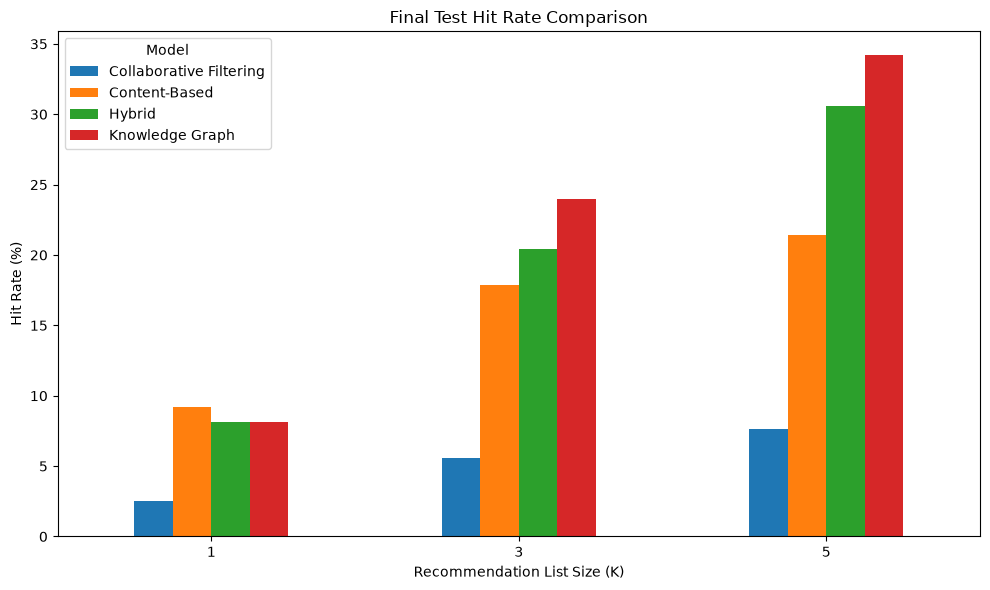

In [16]:
hit_rate_plot_df = (
    final_test_results_df
    .pivot(
        index="K",
        columns="Model",
        values="Hit Rate@K"
    )
    * 100
)

ax = hit_rate_plot_df.plot(
    kind="bar",
    figsize=(10, 6)
)

ax.set_title(
    "Final Test Hit Rate Comparison"
)

ax.set_xlabel(
    "Recommendation List Size (K)"
)

ax.set_ylabel(
    "Hit Rate (%)"
)

ax.legend(
    title="Model"
)

plt.xticks(
    rotation=0
)

plt.tight_layout()

plt.show()

In [17]:
final_experiment_path = (
    experiments_path
    / "FINAL_EVAL_001"
)

final_experiment_path.mkdir(
    parents=True,
    exist_ok=True
)

In [18]:
final_config = {
    "run_id": "FINAL_EVAL_001",
    "dataset_version": "synthetic_v1",
    "random_seed": 42,

    "models": [
        "Content-Based",
        "Collaborative Filtering",
        "Knowledge Graph",
        "Hybrid"
    ],

    "hybrid_weights": {
        "cbf": 0.30,
        "cf": 0.30,
        "kg": 0.40
    },

    "hybrid_weights_selected_using":
        "validation dataset",

    "test_dataset_used_for_tuning":
        False,

    "evaluation_data":
        "reserved test dataset",

    "metrics": [
        "Precision@K",
        "Recall@K",
        "Hit Rate@K",
        "MAP@K"
    ],

    "k_values": [
        1,
        3,
        5
    ]
}


with open(
    final_experiment_path / "config.json",
    "w"
) as file:

    json.dump(
        final_config,
        file,
        indent=4
    )


final_test_results_df.to_csv(
    final_experiment_path
    / "test_metrics.csv",
    index=False
)


test_scores_df.to_csv(
    final_experiment_path
    / "test_component_scores.csv",
    index=False
)

print(
    "Final metrics and scores saved."
)

Final metrics and scores saved.


In [19]:
top5_prediction_records = []


for model_name, score_column in (
    model_score_columns.items()
):

    for _, row in test_df.iterrows():

        task_id = row["task_id"]
        relevant_agent = row["agent_id"]

        ranking = (
            test_scores_df[
                test_scores_df["task_id"]
                == task_id
            ]
            .sort_values(
                score_column,
                ascending=False
            )
            .head(5)
            .reset_index(drop=True)
        )


        for index, prediction in ranking.iterrows():

            top5_prediction_records.append({
                "model":
                    model_name,

                "task_id":
                    task_id,

                "relevant_agent_id":
                    relevant_agent,

                "recommended_agent_id":
                    prediction["agent_id"],

                "rank":
                    index + 1,

                "score":
                    prediction[
                        score_column
                    ],

                "is_relevant":
                    int(
                        prediction["agent_id"]
                        == relevant_agent
                    )
            })


final_top5_predictions_df = pd.DataFrame(
    top5_prediction_records
)


final_top5_predictions_df.to_csv(
    final_experiment_path
    / "test_predictions_k5.csv",
    index=False
)


print(
    "Final test predictions saved."
)

for file in final_experiment_path.iterdir():
    print("-", file.name)

Final test predictions saved.
- config.json
- test_component_scores.csv
- test_metrics.csv
- test_predictions_k5.csv


## Conclusion

The final evaluation was performed using the previously reserved test dataset after model development and hybrid weight selection had been completed.

The Knowledge Graph recommender achieved the strongest overall Top-5 test performance, reaching a Hit Rate@5 of approximately 34.18%.

The Hybrid Recommender achieved a Hit Rate@5 of approximately 30.61%. Although it did not outperform the Knowledge Graph on the final test dataset, it provides an integrated approach that combines content compatibility, collaborative historical behaviour and graph-based relationships.

The difference between validation and test performance highlights the importance of evaluating recommendation systems using previously unseen data and avoiding further model tuning after test results have been observed.

Collaborative Filtering produced the weakest performance, which is consistent with the limited number of task types and relatively sparse interaction history available in the development dataset.

These findings are based on synthetic development data. Evaluation must be repeated using approved real industry data before making claims regarding real-world operational performance.